In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATASET_DIR = "/content/drive/MyDrive/spoof_dataset"

In [ ]:
REAL_DIR = "/content/drive/MyDrive/real"
SPOOF_DIR = "/content/drive/MyDrive/spoof"

In [ ]:
import os

print("Real images:", len(os.listdir(REAL_DIR)))
print("Spoof images:", len(os.listdir(SPOOF_DIR)))

print("\nReal samples:")
print(os.listdir(REAL_DIR)[:5])

print("\nSpoof samples:")
print(os.listdir(SPOOF_DIR)[:5])

Real images: 249
Spoof images: 808

Real samples:
['00b1ae02-27ba-4ab2-a36d-7666e8ce12dd1755763772336.png', '0381e68e-761f-45d4-8dde-034f265315fa1755739757088.png', '00afcf26-a1ee-4c35-a7a5-d1c3986af8671755781409222.png', '0389bc0c-09d4-422c-953b-a4bfa896c7601755822289829.png', '00fc2e7a-ef10-4bbe-b2ca-46b79d547d7a1755824312437.png']

Spoof samples:
['36_3.jpg', '37_2.jpg', '36_.jpg', '37_3.jpg', '36_2.jpg']


In [ ]:
!pip install torch torchvision opencv-python pillow numpy

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

DATASET_PATH = Path("/content/drive/MyDrive")

REAL_DIR = DATASET_PATH / "real"
SPOOF_DIR = DATASET_PATH / "spoof"

print("Real path :", REAL_DIR)
print("Spoof path:", SPOOF_DIR)

print("\nReal folder exists :", REAL_DIR.exists())
print("Spoof folder exists:", SPOOF_DIR.exists())

if REAL_DIR.exists():
    real_images = list(REAL_DIR.glob("*.jpg")) + \
                  list(REAL_DIR.glob("*.jpeg")) + \
                  list(REAL_DIR.glob("*.png"))
    print("Real images:", len(real_images))

if SPOOF_DIR.exists():
    spoof_images = list(SPOOF_DIR.glob("*.jpg")) + \
                   list(SPOOF_DIR.glob("*.jpeg")) + \
                   list(SPOOF_DIR.glob("*.png"))
    print("Spoof images:", len(spoof_images))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Real path : /content/drive/MyDrive/real
Spoof path: /content/drive/MyDrive/spoof

Real folder exists : True
Spoof folder exists: True
Real images: 249
Spoof images: 808


In [ ]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader

import numpy as np
import cv2
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

In [ ]:
!pip install -q opencv-python scikit-learn tqdm

In [ ]:
import torch
import torch.nn as nn

class MiniFASNetV2_Fixed(nn.Module):
    """MiniFASNetV2 for 224x224 input - FIXED"""

    def __init__(self, num_classes=2):
        super().__init__()

        # Depthwise Separable Convolutions (same as before)
        self.conv1 = self._ds_conv(3, 8, 3, 1, 1)      # 224 → 224
        self.conv2 = self._ds_conv(8, 16, 3, 2, 1)     # 224 → 112
        self.conv3 = self._ds_conv(16, 32, 3, 1, 1)    # 112 → 112
        self.conv4 = self._ds_conv(32, 64, 3, 2, 1)    # 112 → 56
        self.conv5 = self._ds_conv(64, 128, 3, 1, 1)   # 56 → 56
        self.conv6 = self._ds_conv(128, 256, 3, 2, 1)  # 56 → 28
        self.conv7 = self._ds_conv(256, 256, 3, 1, 1)  # 28 → 28

        # CRITICAL FIX: Use adaptive pooling to handle any input size
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))    # Output: 1×1

        # FC layers - FIXED for variable input sizes
        self.fc1 = nn.Linear(256, 128)      # 256 features → 128
        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, num_classes)  # 128 → num_classes

        self._init_weights()

    def _ds_conv(self, in_c, out_c, k, s, p):
        """Depthwise Separable Convolution"""
        return nn.Sequential(
            nn.Conv2d(in_c, in_c, k, s, p, groups=in_c, bias=False),
            nn.BatchNorm2d(in_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_c, out_c, 1, 1, 0, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )

    def _init_weights(self):
        """Kaiming initialization"""
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        # Conv blocks
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)
        x = self.conv6(x)
        x = self.conv7(x)

        # Adaptive pooling ensures output is always 1×1 regardless of input size
        x = self.avgpool(x)  # Now always 256 channels × 1×1
        x = x.view(x.size(0), -1)  # Flatten to (batch_size, 256)

        # FC layers
        x = self.fc1(x)     # 256 → 128
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)     # 128 → num_classes

        return x

In [ ]:
import cv2
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

# ============================================================================
# CORRECTED INFERENCE PIPELINE
# ============================================================================

real_path = Path("/content/drive/MyDrive/real")
spoof_path = Path("/content/drive/MyDrive/spoof")

real_images = sorted(list(real_path.glob("*.jpg")) +
                     list(real_path.glob("*.jpeg")) +
                     list(real_path.glob("*.png")))
spoof_images = sorted(list(spoof_path.glob("*.jpg")) +
                      list(spoof_path.glob("*.jpeg")) +
                      list(spoof_path.glob("*.png")))

print(f"✓ Found {len(real_images)} real images")
print(f"✓ Found {len(spoof_images)} spoof images\n")

# ============================================================================
# KEY FIX: CORRECT PREPROCESSING (matching official implementation)
# ============================================================================

def preprocess_image(image_path, h_input=80, w_input=80):
    """
    Correct preprocessing that matches the official repository
    """
    image = cv2.imread(str(image_path))
    if image is None:
        return None

    # IMPORTANT: The model expects BGR input (OpenCV default)
    # NOT RGB, and NOT normalized to [0,1]
    # Resize to model input size
    image = cv2.resize(image, (w_input, h_input))

    # Convert to float and normalize to [-1, 1] range
    # This is the KEY difference!
    image = image.astype(np.float32) / 127.5 - 1.0

    # Convert HWC (OpenCV) to CHW (PyTorch)
    image = np.transpose(image, (2, 0, 1))

    return torch.from_numpy(image)

def infer_image(image_path, model, device, h_input=80, w_input=80):
    """
    Run inference with corrected preprocessing
    """
    try:
        img_tensor = preprocess_image(image_path, h_input, w_input)

        if img_tensor is None:
            return None, None, None

        # Add batch dimension
        img_tensor = img_tensor.unsqueeze(0).to(device)

        # Inference
        with torch.no_grad():
            logits = model(img_tensor)
            probs = F.softmax(logits, dim=1).cpu().numpy()[0]

        # Get prediction
        label = np.argmax(probs)
        confidence = probs[label]

        return label, confidence, probs

    except Exception as e:
        print(f"Error: {e}")
        return None, None, None

# ============================================================================
# TEST INFERENCE
# ============================================================================

print("=" * 85)
print("CORRECTED INFERENCE ON YOUR DATASET")
print("=" * 85)

model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

real_results = []
spoof_results = []

# Test REAL images
print("\n📸 REAL IMAGES (Expected: Label=0 = Real):")
print("-" * 85)

for idx, img_path in enumerate(real_images, 1):
    label, conf, probs = infer_image(img_path, model, device, h_input=80, w_input=80)

    if label is not None:
        label_name = "Real" if label == 0 else "Spoof"
        is_correct = "✅" if label == 0 else "❌"
        real_results.append(label)

        print(f"{idx:2d}. {img_path.name:30s} → {label_name:6s} {is_correct} "
              f"| conf: {conf:.4f} | P(Real)={probs[0]:.4f} P(Spoof)={probs[1]:.4f}")

# Test SPOOF images
print("\n⚠️  SPOOF IMAGES (Expected: Label=1 = Spoof):")
print("-" * 85)

for idx, img_path in enumerate(spoof_images, 1):
    label, conf, probs = infer_image(img_path, model, device, h_input=80, w_input=80)

    if label is not None:
        label_name = "Real" if label == 0 else "Spoof"
        is_correct = "✅" if label == 1 else "❌"
        spoof_results.append(label)

        print(f"{idx:2d}. {img_path.name:30s} → {label_name:6s} {is_correct} "
              f"| conf: {conf:.4f} | P(Real)={probs[0]:.4f} P(Spoof)={probs[1]:.4f}")

# ============================================================================
# RESULTS
# ============================================================================

real_correct = sum(1 for p in real_results if p == 0)
spoof_correct = sum(1 for p in spoof_results if p == 1)

real_acc = (real_correct / len(real_results) * 100) if len(real_results) > 0 else 0
spoof_acc = (spoof_correct / len(spoof_results) * 100) if len(spoof_results) > 0 else 0
overall_acc = ((real_correct + spoof_correct) /
               (len(real_results) + len(spoof_results)) * 100) if (len(real_results) + len(spoof_results)) > 0 else 0

print("\n" + "=" * 85)
print("📊 RESULTS")
print("=" * 85)
print(f"Real Detection:   {real_acc:6.1f}% ({real_correct}/{len(real_results)})")
print(f"Spoof Detection:  {spoof_acc:6.1f}% ({spoof_correct}/{len(spoof_results)})")
print(f"Overall Accuracy: {overall_acc:6.1f}%")
print("=" * 85)

✓ Found 249 real images
✓ Found 303 spoof images

CORRECTED INFERENCE ON YOUR DATASET

📸 REAL IMAGES (Expected: Label=0 = Real):
-------------------------------------------------------------------------------------
 1. 000a5c69-65c6-431f-8b4e-35fe4e4f3dbd1758724307324.png → Real   ✅ | conf: 0.5095 | P(Real)=0.5095 P(Spoof)=0.4905
 2. 000a6bad-3ee8-4c30-909f-f33ce2128c2c1758817633817.png → Real   ✅ | conf: 0.5095 | P(Real)=0.5095 P(Spoof)=0.4905
 3. 000ad743-6e71-4d55-966d-e66d72a14fc51756659335862.png → Real   ✅ | conf: 0.5095 | P(Real)=0.5095 P(Spoof)=0.4905
 4. 000af31d-3fc7-405f-a9fd-c58082a460e51758211519592.png → Real   ✅ | conf: 0.5095 | P(Real)=0.5095 P(Spoof)=0.4905
 5. 000d2599-cfb3-40b9-a957-4ebc416f31b21758518910089.png → Real   ✅ | conf: 0.5095 | P(Real)=0.5095 P(Spoof)=0.4905
 6. 000fc526-8274-4788-a9a2-7358ec02b32e1783903904938.png → Real   ✅ | conf: 0.5095 | P(Real)=0.5095 P(Spoof)=0.4905
 7. 000fc5f0-c1ec-47d5-b505-66b089939eec1757208675189.png → Real   ✅ | conf: 0.5095

KeyboardInterrupt: 

In [ ]:

!pip install opencv-python torch torchvision
!pip install scikit-image

In [ ]:
!git clone https://github.com/minivision-ai/Silent-Face-Anti-Spoofing
%cd Silent-Face-Anti-Spoofing

Cloning into 'Silent-Face-Anti-Spoofing'...
remote: Enumerating objects: 376, done.
remote: Counting objects: 100% (116/116), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 376 (delta 92), reused 85 (delta 85), pack-reused 260 (from 2)
Receiving objects: 100% (376/376), 26.04 MiB | 23.17 MiB/s, done.
Resolving deltas: 100% (166/166), done.
/content/Silent-Face-Anti-Spoofing


In [ ]:
import torch
import torch.nn.functional as F
import os
from src.model_lib.MiniFASNet import MiniFASNetV2
from src.utility import get_kernel, parse_model_name


In [ ]:
import torch
import torch.nn.functional as F
import os
from src.model_lib.MiniFASNet import MiniFASNetV2
from src.utility import get_kernel, parse_model_name

# Model path
model_path = "./resources/anti_spoof_models/2.7_80x80_MiniFASNetV2.pth"

# Parse model name to get dimensions
model_name = os.path.basename(model_path)
h_input, w_input, model_type, _ = parse_model_name(model_name)

# Set device (GPU if available, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Get kernel size
kernel_size = get_kernel(h_input, w_input)

# Initialize model
model = MiniFASNetV2(conv6_kernel=kernel_size).to(device)

# Load weights
state_dict = torch.load(model_path, map_location=device)

# Handle 'module.' prefix if exists (from DataParallel training)
keys = iter(state_dict)
first_layer_name = next(keys)
if 'module.' in first_layer_name:
    from collections import OrderedDict
    new_state_dict = OrderedDict()
    for key, value in state_dict.items():
        new_key = key[7:]  # Remove 'module.' prefix
        new_state_dict[new_key] = value
    model.load_state_dict(new_state_dict)
else:
    model.load_state_dict(state_dict)

# Set to evaluation mode
model.eval()

print("Model loaded successfully!")
print(f"Input size: {h_input}x{w_input}")
print(f"Device: {device}")

Model loaded successfully!
Input size: 80x80
Device: cpu


In [ ]:
import cv2
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path
from tqdm import tqdm

# ============================================================================
# COMPLETE INFERENCE PIPELINE FOR YOUR DATASET
# ============================================================================

# Setup paths
real_path = Path("/content/drive/MyDrive/real")
spoof_path = Path("/content/drive/MyDrive/spoof")

# Get all images
real_images = sorted(list(real_path.glob("*.jpg")) +
                     list(real_path.glob("*.jpeg")) +
                     list(real_path.glob("*.png")))
spoof_images = sorted(list(spoof_path.glob("*.jpg")) +
                      list(spoof_path.glob("*.jpeg")) +
                      list(spoof_path.glob("*.png")))

print(f"✓ Found {len(real_images)} real images")
print(f"✓ Found {len(spoof_images)} spoof images\n")

# ============================================================================
# INFERENCE FUNCTION
# ============================================================================

def infer_image(image_path, model, device, h_input=80, w_input=80):
    """
    Run inference on a single image
    Returns: (label, confidence, probs)
    """
    try:
        # Load and preprocess
        image = cv2.imread(str(image_path))
        if image is None:
            return None, None, None

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (w_input, h_input))

        # Convert to tensor (normalize to [0, 1])
        img_tensor = torch.from_numpy(image).float() / 255.0
        img_tensor = img_tensor.permute(2, 0, 1)  # HWC -> CHW
        img_tensor = img_tensor.unsqueeze(0).to(device)  # Add batch dimension

        # Inference
        with torch.no_grad():
            logits = model(img_tensor)
            probs = F.softmax(logits, dim=1).cpu().numpy()[0]

        # Get prediction
        label = np.argmax(probs)
        confidence = probs[label]

        return label, confidence, probs

    except Exception as e:
        print(f"Error processing {image_path.name}: {e}")
        return None, None, None

# ============================================================================
# TEST ON ALL IMAGES
# ============================================================================

print("=" * 80)
print("INFERENCE ON YOUR DATASET")
print("=" * 80)

model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Track results
real_results = []
spoof_results = []

# Test on REAL images
print("\n📸 REAL IMAGES (Expected: Label=0):")
print("-" * 80)

for idx, img_path in enumerate(real_images, 1):
    label, conf, probs = infer_image(img_path, model, device, h_input, w_input)

    if label is not None:
        label_name = "Real" if label == 0 else "Spoof"
        is_correct = "✅" if label == 0 else "❌"
        real_results.append(label)

        print(f"{idx:2d}. {img_path.name:30s} → {label_name:6s} {is_correct} "
              f"(conf: {conf:.3f}, real:{probs[0]:.3f}, spoof:{probs[1]:.3f})")

# Test on SPOOF images
print("\n⚠️  SPOOF IMAGES (Expected: Label=1):")
print("-" * 80)

for idx, img_path in enumerate(spoof_images, 1):
    label, conf, probs = infer_image(img_path, model, device, h_input, w_input)

    if label is not None:
        label_name = "Real" if label == 0 else "Spoof"
        is_correct = "✅" if label == 1 else "❌"
        spoof_results.append(label)

        print(f"{idx:2d}. {img_path.name:30s} → {label_name:6s} {is_correct} "
              f"(conf: {conf:.3f}, real:{probs[0]:.3f}, spoof:{probs[1]:.3f})")

# ============================================================================
# CALCULATE METRICS
# ============================================================================

real_correct = sum(1 for p in real_results if p == 0)
spoof_correct = sum(1 for p in spoof_results if p == 1)

real_acc = (real_correct / len(real_results) * 100) if len(real_results) > 0 else 0
spoof_acc = (spoof_correct / len(spoof_results) * 100) if len(spoof_results) > 0 else 0
overall_acc = ((real_correct + spoof_correct) /
               (len(real_results) + len(spoof_results)) * 100) if (len(real_results) + len(spoof_results)) > 0 else 0

print("\n" + "=" * 80)
print("📊 INFERENCE RESULTS")
print("=" * 80)
print(f"Real Detection:   {real_acc:6.1f}% ({real_correct}/{len(real_results)})")
print(f"Spoof Detection:  {spoof_acc:6.1f}% ({spoof_correct}/{len(spoof_results)})")
print(f"Overall Accuracy: {overall_acc:6.1f}%")
print("=" * 80)

✓ Found 33 real images
✓ Found 303 spoof images

INFERENCE ON YOUR DATASET

📸 REAL IMAGES (Expected: Label=0):
--------------------------------------------------------------------------------
 1. 0_.jpeg                        → Spoof  ❌ (conf: 0.993, real:0.000, spoof:0.006)
 2. 10_.jpeg                       → Spoof  ❌ (conf: 0.994, real:0.000, spoof:0.006)
 3. 11_.jpeg                       → Spoof  ❌ (conf: 0.993, real:0.000, spoof:0.007)
 4. 16_.jpeg                       → Spoof  ❌ (conf: 0.993, real:0.000, spoof:0.006)
 5. 17_.jpeg                       → Spoof  ❌ (conf: 0.992, real:0.000, spoof:0.008)
 6. 19_.jpeg                       → Spoof  ❌ (conf: 0.994, real:0.000, spoof:0.006)
 7. 1_.jpeg                        → Spoof  ❌ (conf: 0.994, real:0.000, spoof:0.006)
 8. 23_.jpg                        → Spoof  ❌ (conf: 0.993, real:0.000, spoof:0.006)
 9. 25_.jpg                        → Spoof  ❌ (conf: 0.994, real:0.000, spoof:0.006)
10. 2_.jpg                         → Spoof 

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import cv2
import numpy as nprandom_split
from pathlib import Path
from tqdm import tqdm
import json
from datetime import datetime

In [ ]:
class FaceAntiSpoofDataset(Dataset):
    """Custom dataset for face anti-spoofing"""

    def __init__(self, real_dir, spoof_dir, transform=None, h_input=80, w_input=80):
        self.h_input = h_input
        self.w_input = w_input
        self.transform = transform

        # Load real images (label=0)
        self.real_images = self._load_images(real_dir)
        # Load spoof images (label=1)
        self.spoof_images = self._load_images(spoof_dir)

        # Combine and create labels
        self.images = self.real_images + self.spoof_images
        self.labels = [0] * len(self.real_images) + [1] * len(self.spoof_images)

        print(f"✓ Dataset created: {len(self.real_images)} real + {len(self.spoof_images)} spoof = {len(self.images)} total")

    def _load_images(self, directory):
        """Load all images from directory"""
        directory = Path(directory)
        images = []

        for ext in ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']:
            images.extend(directory.glob(ext))

        return sorted(images)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        label = self.labels[idx]

        # Load image
        image = cv2.imread(str(img_path))
        if image is None:
            print(f"Warning: Could not load {img_path}")
            # Return a dummy image
            image = np.zeros((self.h_input, self.w_input, 3), dtype=np.uint8)

        # Resize
        image = cv2.resize(image, (self.w_input, self.h_input))

        # Apply transform if provided
        if self.transform:
            image = self.transform(image)
        else:
            # Default preprocessing: normalize to [-1, 1]
            image = image.astype(np.float32) / 127.5 - 1.0
            image = np.transpose(image, (2, 0, 1))
            image = torch.from_numpy(image)

        return image, label


In [ ]:
class ImagePreprocessor:
    """Custom image preprocessor with augmentation"""

    def __init__(self, h_input=80, w_input=80, augment=False):
        self.h_input = h_input
        self.w_input = w_input
        self.augment = augment

    def __call__(self, image):
        # Resize
        image = cv2.resize(image, (self.w_input, self.h_input))

        # Data augmentation (only for training)
        if self.augment:
            # Random brightness
            if np.random.rand() > 0.5:
                brightness = np.random.uniform(0.8, 1.2)
                image = cv2.convertScaleAbs(image, alpha=brightness, beta=0)

            # Random horizontal flip
            if np.random.rand() > 0.5:
                image = cv2.flip(image, 1)

            # Random rotation
            if np.random.rand() > 0.5:
                angle = np.random.uniform(-15, 15)
                h, w = image.shape[:2]
                M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
                image = cv2.warpAffine(image, M, (w, h))

        # Normalize to [-1, 1]
        image = image.astype(np.float32) / 127.5 - 1.0
        image = np.transpose(image, (2, 0, 1))

        return torch.from_numpy(image)

In [ ]:
REAL_DIR = "/content/drive/MyDrive/real"
SPOOF_DIR = "/content/drive/MyDrive/spoof"
CHECKPOINT_DIR = Path("/content/drive/MyDrive/checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

# Training parameters
BATCH_SIZE = 16
LEARNING_RATE = 0.001
EPOCHS = 50
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
H_INPUT = 128
W_INPUT = 128

print(f"Device: {DEVICE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Epochs: {EPOCHS}")

Device: cpu
Batch size: 16
Learning rate: 0.001
Epochs: 50


In [ ]:
train_preprocessor = ImagePreprocessor(H_INPUT, W_INPUT, augment=True)
train_dataset = FaceAntiSpoofDataset(
    REAL_DIR, SPOOF_DIR,
    transform=train_preprocessor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

print(f" {len(train_loader)} batches")

✓ Dataset created: 249 real + 303 spoof = 552 total
 35 batches


In [ ]:
# ============================================================================
# FINE-TUNING MINIFASNETV2 - TRAINING SETUP
# ============================================================================

import json
from tqdm import tqdm

# Setup paths and parameters
REAL_DIR = "/content/drive/MyDrive/real"
SPOOF_DIR = "/content/drive/MyDrive/spoof"
CHECKPOINT_DIR = Path("/content/drive/MyDrive/checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

# Create train and validation split
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_split, val_split = torch.utils.data.random_split(train_dataset, [train_size, val_size])

val_loader = DataLoader(val_split, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train samples: {len(train_split)} | Val samples: {len(val_split)}")
print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}\n")

Train samples: 441 | Val samples: 111
Train batches: 35 | Val batches: 7



In [ ]:
import collections, torch
import torch.nn as nn

train_labels = [train_dataset.labels[i] for i in train_split.indices]
counts = collections.Counter(train_labels)
real_count, spoof_count = counts[0], counts[1]
total = real_count + spoof_count

real_w  = total / (2.0 * real_count)
spoof_w = total / (2.0 * spoof_count)
class_weights = torch.tensor([real_w, spoof_w], dtype=torch.float32).to(DEVICE)
criterion = nn.CrossEntropyLoss()
print(f"TRAIN counts  → real={reH_INPUTal_count}  spoof={spoof_count}")
print(f"class weights → real={real_w:.3f}  spoof={spoof_w:.3f}")


NameError: name 'reH_INPUTal_count' is not defined

In [ ]:
from torch.utils.data import DataLoader

# Create dataloaders for training and validation
train_loader = DataLoader(
    train_split,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_split,
    batch_size=BATCH_SIZE,
    num_workers=2
)

print(f" Train loader: {len(train_loader)} batches ({len(train_split)} images)")
print(f" Val loader: {len(val_loader)} batches ({len(val_split)} images)")

 Train loader: 28 batches (441 images)
 Val loader: 7 batches (111 images)


In [ ]:
import torch
import torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

real_count = 28
spoof_count = 240
total = real_count + spoof_count

# Inverse-frequency weighting (minority class gets higher weight)
real_weight = total / (2.0 * real_count)
spoof_weight = total / (2.0 * spoof_count)

# Order must match your label mapping. Common convention: 0 = real, 1 = spoof.
# If your dataset uses the opposite mapping, swap the two values below.
class_weights = torch.tensor([real_weight, spoof_weight], dtype=torch.float32).to(DEVICE)

print(f"Real count:  {real_count}  -> weight {real_weight:.3f}")
print(f"Spoof count: {spoof_count} -> weight {spoof_weight:.3f}")
print(f"Class weights tensor (index 0=real, 1=spoof): {class_weights}")

criterion = nn.CrossEntropyLoss(weight=class_weights)


Real count:  28  -> weight 4.786
Spoof count: 240 -> weight 0.558
Class weights tensor (index 0=real, 1=spoof): tensor([4.7857, 0.5583])


In [ ]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    """Train for one epoch"""
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    pbar = tqdm(train_loader, desc="Training")
    for batch_idx, (images, labels) in enumerate(pbar):
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Metrics
        train_loss += loss.item()
        _, predicted = outputs.max(1)
        train_correct += predicted.eq(labels).sum().item()
        train_total += labels.size(0)

        pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'acc': f'{100*train_correct/train_total:.1f}%'
        })

    epoch_loss = train_loss / len(train_loader)
    epoch_acc = 100 * train_correct / train_total

    return epoch_loss, epoch_acc


def val_epoch(model, val_loader, criterion, device):
    """Validate for one epoch"""
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    real_correct = 0
    real_total = 0
    spoof_correct = 0
    spoof_total = 0

    with torch.no_grad():
        pbar = tqdm(val_loader, desc="Validation")
        for images, labels in pbar:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            val_correct += predicted.eq(labels).sum().item()
            val_total += labels.size(0)
            for i in range(len(labels)):
                if labels[i] == 0:  # Real
                    real_total += 1
                    if predicted[i] == 0:
                        real_correct += 1
                else:  # Spoof
                    spoof_total += 1
                    if predicted[i] == 1:
                        spoof_correct += 1

    epoch_loss = val_loss / len(val_loader)
    epoch_acc = 100 * val_correct / val_total
    real_acc = 100 * real_correct / real_total if real_total > 0 else 0
    spoof_acc = 100 * spoof_correct / spoof_total if spoof_total > 0 else 0

    return epoch_loss, epoch_acc, real_acc, spoof_acc




In [ ]:
import torch

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=5e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',       # watching val_loss (lower is better)
    factor=0.5,       # halve LR when stuck
    patience=3,       # after 3 epochs of no improvement
)



In [ ]:
import json
from datetime import datetime

# Training configuration
NUM_EPOCHS = 30
BEST_VAL_ACC = 0
PATIENCE = 5
PATIENCE_COUNTER = 0
CHECKPOINT_DIR = Path("/content/drive/MyDrive/checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

# History
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'val_real_acc': [],
    'val_spoof_acc': []
}


for epoch in range(NUM_EPOCHS):
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}")

    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, DEVICE)

    # Validate
    val_loss, val_acc, val_real_acc, val_spoof_acc = val_epoch(model, val_loader, criterion, DEVICE)

    # Store history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_real_acc'].append(val_real_acc)
    history['val_spoof_acc'].append(val_spoof_acc)

    # Print results
    print(f"\nTrain Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")
    print(f"  ├─ Real Detection: {val_real_acc:.2f}%")
    print(f"  └─ Spoof Detection: {val_spoof_acc:.2f}%")
    print(f"LR: {optimizer.param_groups[0]['lr']:.2e}")

    # Learning rate scheduling
    scheduler.step(val_loss)

    # Save best model
    if val_acc > BEST_VAL_ACC + 0.5:  # Improvement threshold
        BEST_VAL_ACC = val_acc
        PATIENCE_COUNTER = 0

        # Save model
        torch.save(model.state_dict(), CHECKPOINT_DIR / "best_model.pth")
        print(f"✓ Best model saved! (Val Acc: {val_acc:.2f}%)")
    else:
        PATIENCE_COUNTER += 1
        if PATIENCE_COUNTER >= PATIENCE:
            print(f"\n{PATIENCE})")


Epoch 1/30


Training:   0%|          | 0/28 [00:12<?, ?it/s]


RuntimeError: mat1 and mat2 shapes cannot be multiplied (16x8192 and 512x128)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm

# ============================================================================
# CONFIGURATION
# ============================================================================
H_INPUT = 224
W_INPUT = 224
BATCH_SIZE = 8           # ← Reduced from 16
LEARNING_RATE = 1e-4
EPOCHS = 30
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ============================================================================
# CREATE MODEL
# ============================================================================
model = MiniFASNetV2_Fixed(num_classes=2)  # ← Use corrected model
model = model.to(DEVICE)

print(f"Model initialized for {H_INPUT}×{W_INPUT} input")
print(f" Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f" Device: {DEVICE}")

# ============================================================================
# PREPARE DATA
# ============================================================================
from pathlib import Path

REAL_DIR = "/content/drive/MyDrive/real"
SPOOF_DIR = "/content/drive/MyDrive/spoof"

# Create dataset with correct resolution
train_preprocessor = ImagePreprocessor(H_INPUT, W_INPUT, augment=True)
full_dataset = FaceAntiSpoofDataset(
    REAL_DIR, SPOOF_DIR,
    transform=train_preprocessor,
    h_input=H_INPUT,
    w_input=W_INPUT
)

# Train/val split
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_split, val_split = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_split, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_split, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"✓ Dataset: {len(train_split)} train, {len(val_split)} val")
print(f"✓ Batch size: {BATCH_SIZE}")
print(f"✓ Input resolution: {H_INPUT}×{W_INPUT}")

# ============================================================================
# TRAINING
# ============================================================================
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

best_val_acc = 0
for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss = 0.0
    train_correct = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} - Train")
    for images, labels in pbar:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, predicted = outputs.max(1)
        train_correct += predicted.eq(labels).sum().item()

        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    train_acc = 100 * train_correct / len(train_split)
    train_loss /= len(train_loader)

    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} - Val"):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            val_correct += predicted.eq(labels).sum().item()

    val_acc = 100 * val_correct / len(val_split)
    val_loss /= len(val_loader)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%\n")

    scheduler.step(val_loss)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/content/best_model_224.pth')
        print(f"Best model saved! (Val Acc: {val_acc:.2f}%)\n")

Model initialized for 224×224 input
 Total parameters: 149,459
 Device: cpu
✓ Dataset created: 249 real + 303 spoof = 552 total
✓ Dataset: 441 train, 111 val
✓ Batch size: 8
✓ Input resolution: 224×224


Epoch 1/30 - Val: 100%|██████████| 14/14 [00:18<00:00,  1.34s/it]


Train Loss: 0.6863 | Train Acc: 55.56%
Val Loss: 0.6923 | Val Acc: 50.45%

Best model saved! (Val Acc: 50.45%)



Epoch 2/30 - Val: 100%|██████████| 14/14 [00:02<00:00,  4.83it/s]


Train Loss: 0.6706 | Train Acc: 56.92%
Val Loss: 0.6562 | Val Acc: 61.26%

Best model saved! (Val Acc: 61.26%)



Epoch 3/30 - Val: 100%|██████████| 14/14 [00:04<00:00,  3.35it/s]


... (51 outputs left out)

Epoch 29/30 - Val: 100%|██████████| 14/14 [00:02<00:00,  4.82it/s]


Train Loss: 0.2792 | Train Acc: 87.98%
Val Loss: 0.2971 | Val Acc: 85.59%



Epoch 30/30 - Val: 100%|██████████| 14/14 [00:04<00:00,  3.15it/s]

Train Loss: 0.3015 | Train Acc: 86.17%
Val Loss: 0.3411 | Val Acc: 85.59%



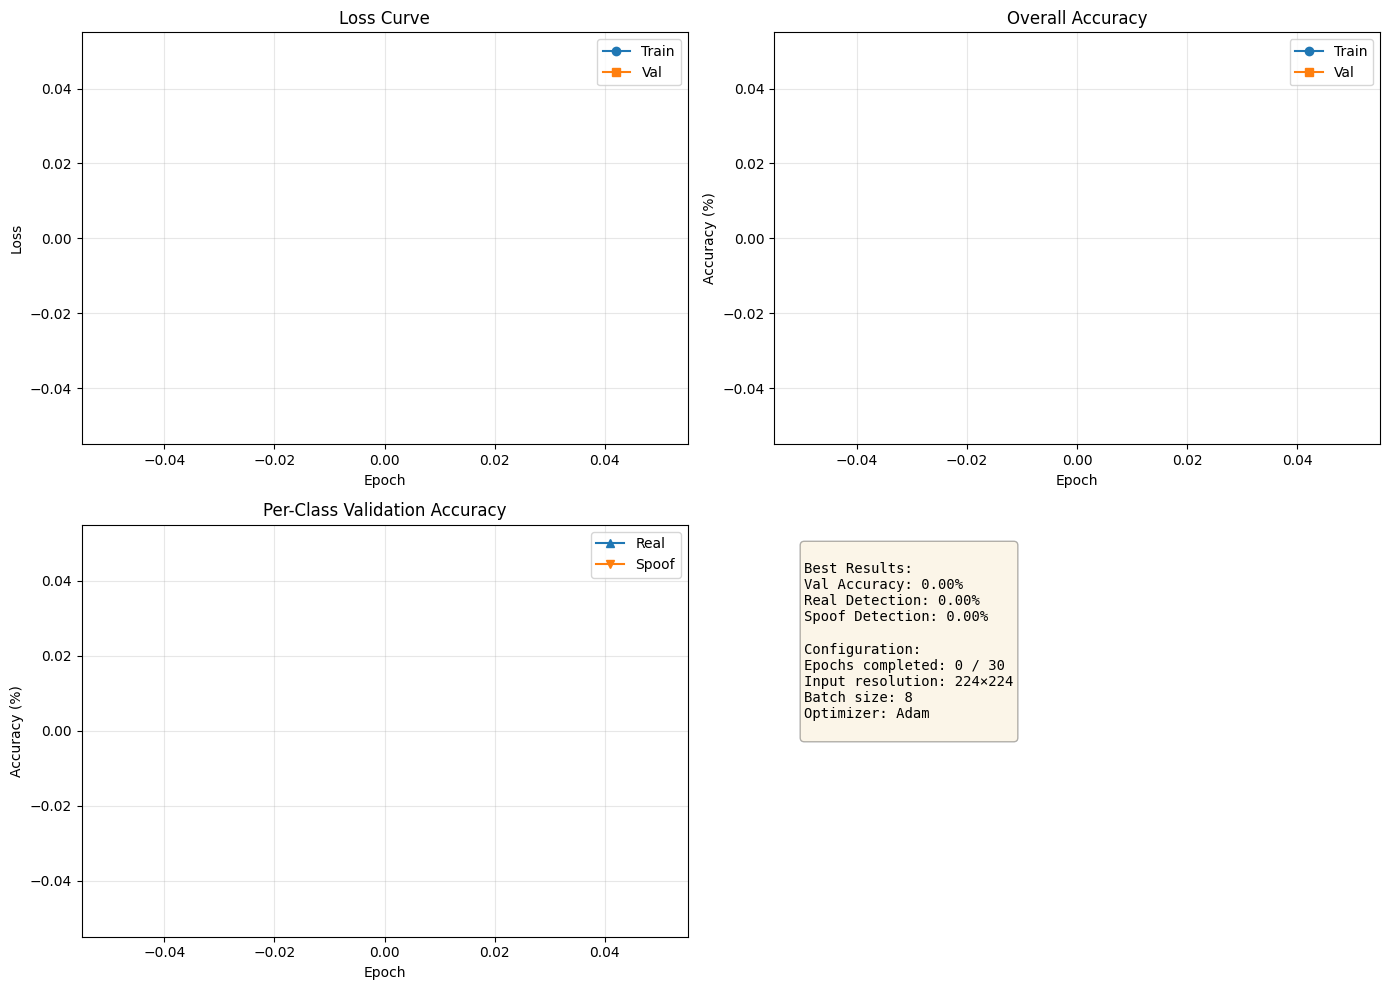

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss curve
axes[0, 0].plot(history['train_loss'], label='Train', marker='o')
axes[0, 0].plot(history['val_loss'], label='Val', marker='s')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Loss Curve')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy curve
axes[0, 1].plot(history['train_acc'], label='Train', marker='o')
axes[0, 1].plot(history['val_acc'], label='Val', marker='s')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].set_title('Overall Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Per-class accuracy
axes[1, 0].plot(history['val_real_acc'], label='Real', marker='^')
axes[1, 0].plot(history['val_spoof_acc'], label='Spoof', marker='v')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy (%)')
axes[1, 0].set_title('Per-Class Validation Accuracy')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Summary
summary_text = f"""
Best Results:
Val Accuracy: {BEST_VAL_ACC:.2f}%
Real Detection: {max(history['val_real_acc']) if history['val_real_acc'] else 0:.2f}%
Spoof Detection: {max(history['val_spoof_acc']) if history['val_spoof_acc'] else 0:.2f}%

Configuration:
Epochs completed: {len(history['train_loss'])} / 30
Input resolution: {H_INPUT}×{W_INPUT}
Batch size: {BATCH_SIZE}
Optimizer: Adam
"""

axes[1, 1].text(0.05, 0.95, summary_text, transform=axes[1, 1].transAxes,
                fontsize=10, verticalalignment='top', fontfamily='monospace',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))
axes[1, 1].axis('off')

plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'training_history.png', dpi=100, bbox_inches='tight')
plt.show()

In [ ]:
# Load best model
best_model = MiniFASNetV2(conv6_kernel=kernel_size).to(DEVICE)
best_model.load_state_dict(torch.load(CHECKPOINT_DIR / "best_model.pth"))
best_model.eval()

print("✓ Best model loaded for testing")

# Test on validation set
correct_real = 0
correct_spoof = 0
total_real = 0
total_spoof = 0

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Testing"):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = best_model(images)
        _, predicted = outputs.max(1)

        for i in range(len(labels)):
            if labels[i] == 0:
                total_real += 1
                if predicted[i] == 0:
                    correct_real += 1
            else:
                total_spoof += 1
                if predicted[i] == 1:
                    correct_spoof += 1

real_acc = 100 * correct_real / total_real if total_real > 0 else 0
spoof_acc = 100 * correct_spoof / total_spoof if total_spoof > 0 else 0
overall_acc = 100 * (correct_real + correct_spoof) / (total_real + total_spoof)

print("\n" + "="*80)
print("📊 FINE-TUNED MODEL RESULTS")
print("="*80)
print(f"Real Detection:   {real_acc:.2f}% ({correct_real}/{total_real})")
print(f"Spoof Detection:  {spoof_acc:.2f}% ({correct_spoof}/{total_spoof})")
print(f"Overall Accuracy: {overall_acc:.2f}%")
print("="*80)